In [2]:
import sys
sys.path.append(".")
from olist_utils import run_query, set_style, COLORS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
set_style()

集中度：头部卖家贡献了多少 GMV； 方法：帕累托曲线

In [ ]:
sql_pareto = """
WITH ranked AS (
    SELECT seller_id, gmv,
           ROW_NUMBER() OVER (ORDER BY gmv DESC, seller_id) AS gmv_rank,
           COUNT(*)     OVER ()                             AS n_sellers,
           SUM(gmv)     OVER (ORDER BY gmv DESC, seller_id) AS cum_gmv,
           SUM(gmv)     OVER ()                             AS total_gmv
    FROM dws_seller
)
SELECT gmv_rank,
       gmv,
       ROUND(gmv_rank / n_sellers, 4) AS seller_share,
       ROUND(cum_gmv / total_gmv, 4)  AS gmv_share
FROM ranked
ORDER BY gmv_rank;
"""
df_pareto = run_query(sql_pareto)
df_pareto[["seller_share", "gmv_share"]] = df_pareto[["seller_share", "gmv_share"]].astype(float)

print(len(df_pareto), df_pareto["gmv_share"].iloc[-1])          
print(df_pareto.loc[df_pareto["gmv_rank"] == 29, "gmv_share"])   
print("卖家 GMV 中位数：", df_pareto["gmv"].median())

2945 1.0
28    0.2552
Name: gmv_share, dtype: float64
卖家 GMV 中位数： 849.7


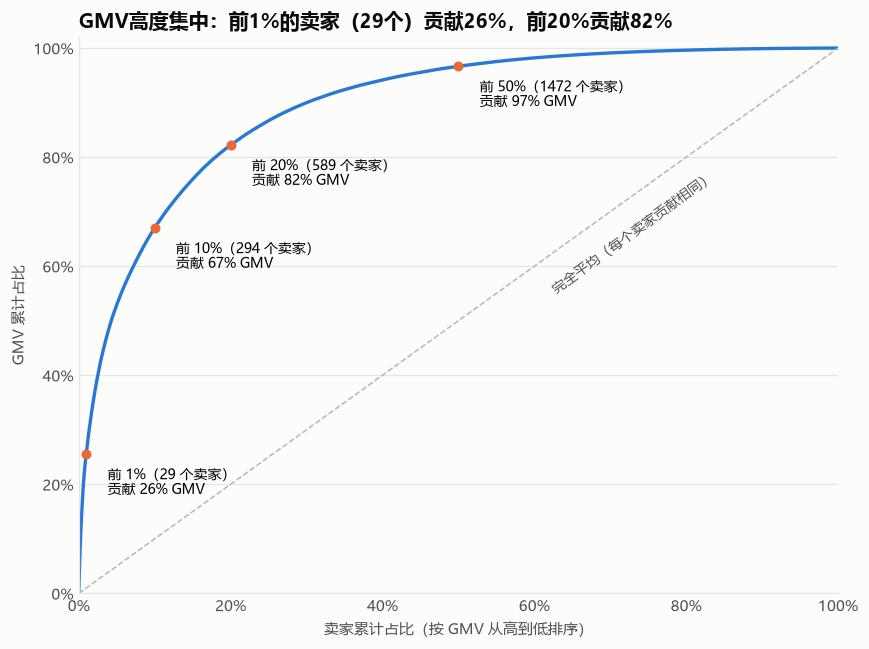

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))

# 曲线从原点出发：在最前面补一个 (0, 0)
x = pd.concat([pd.Series([0.0]), df_pareto["seller_share"]])
y = pd.concat([pd.Series([0.0]), df_pareto["gmv_share"]])
ax.plot(x, y, color=COLORS["blue"], linewidth=2.2)

# 对角线：如果每个卖家贡献完全相同，曲线就是这条线
ax.plot([0, 1], [0, 1], color=COLORS["gray"], linestyle="--", linewidth=1)
ax.text(0.62, 0.55, "完全平均（每个卖家贡献相同）",
        color=COLORS["text_secondary"], fontsize=9, rotation=36)

# 标注前 1% / 10% / 20% / 50%
for k in [0.01, 0.10, 0.20, 0.5]:
    r = df_pareto[df_pareto["seller_share"] <= k + 1e-9].iloc[-1]
    ax.scatter(r["seller_share"], r["gmv_share"], color=COLORS["orange"], zorder=3, s=30)
    ax.annotate(f"前 {k:.0%}（{int(r['gmv_rank'])} 个卖家）\n贡献 {r['gmv_share']:.0%} GMV",
                (r["seller_share"], r["gmv_share"]),
                xytext=(14, -26), textcoords="offset points", fontsize=9)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel("卖家累计占比（按 GMV 从高到低排序）")
ax.set_ylabel("GMV 累计占比")
ax.set_title("GMV高度集中：前1%的卖家（29个）贡献26%，前20%贡献82%", loc="left")

fig.tight_layout()
fig.savefig("../docs/figures/m6_pareto.png", dpi=150, bbox_inches="tight")
plt.show()